# HIT-UAV Thermal Detection
### Real-time YOLOv8 detection of people and vehicles in high-altitude UAV infrared thermal imagery

---

## Project Overview

This project aims to perform deep-learning-based object detection on **infrared thermal images captured from high altitude (60–130 m)**. The primary application area is real-time target identification and tracking for guided systems and unmanned aerial vehicles (UAVs).

### Why Thermal Imagery?

| Property | RGB Camera | Thermal Camera |
|---|---|---|
| Visibility | Requires light | Works in darkness |
| Concealment | Vulnerable to color camouflage | Captures heat signature |
| Weather | Affected by rain/fog | Relatively robust |
| Night use | Limited | Fully effective |
| Model training | Abundant data available | **Little data → transfer learning required** |

---

## Project Methodology

```
[1] Data Preparation      [2] Spatial Filtering      [3] Preprocessing
 Kaggle → HIT-UAV    →    Classical filters    →    Median+CLAHE+Unsharp
 43,470 frames            (all filters)             dataset → processed
 → 2,866 images           EDA visualization         dataset/hit-uav-processed/

[4] Data Split            [5] Model Training         [6] Evaluation
 70% Train           →    YOLOv8n                →   mAP50, P, R, F1
 20% Test                 Transfer Learning           Per-class analysis
 10% Val                  50 epochs, img=640          Confusion Matrix
```

---

## Dataset: HIT-UAV

| Parameter | Value |
|---|---|
| Total Video Frames | 43,470 |
| Images Used | **2,866** labeled images in the Kaggle release (the paper samples 2,898: 1 every 15 frames, 7 FPS sensor) |
| Image Type | Infrared Thermal |
| Flight Altitude | 60 – 130 meters |
| Camera Angle | 30° – 90° (nadir view) |
| Label Format | YOLO (x_center, y_center, width, height — normalized) |
| Number of Classes | **4** |

### Target Classes

| ID | Class | Description | Difficulty |
|---|---|---|---|
| 0 | Person | Pedestrian | ★★★ (small, variable heat) |
| 1 | Car | Passenger car | ★★ (large, distinct heat) |
| 2 | Motorcycle | Motorcycle / Bicycle | ★★★ (small, engine heat) |
| 3 | Other Vehicle | Trucks, buses, etc. | ★ (large, diverse) |

---

## What This Notebook Covers

1. **Spatial filtering** on thermal frames: smoothing, sharpening and edge operators, with the underlying math
2. **Linear vs. nonlinear** operators and when each one is the right tool
3. A **thermal-specific preprocessing pipeline** (Median → CLAHE → Unsharp Masking)
4. **YOLOv8n transfer learning** on HIT-UAV
5. Evaluation with **mAP, Precision, Recall** on a held-out test split
6. Exporting the trained model to the FastAPI + Next.js demo app

## Section 2 — Environment Setup and Data Integration

### 2.1 Google Colab Configuration

> **Runtime:** Google Colab (T4 GPU recommended)
> **Menu:** `Runtime → Change runtime type → T4 GPU`

In this section:
1. The notebook detects whether it runs on **Colab** or **locally** and sets paths accordingly
2. The Kaggle API token is loaded securely via **Colab Secrets** (locally: `~/.kaggle/kaggle.json`)
3. The HIT-UAV dataset is downloaded from Kaggle (skipped if it already exists)

| Environment | Dataset root | Training outputs |
|---|---|---|
| Colab | `/content/dataset/` | `/content/runs/detect/train/` |
| Local | `<repo>/dataset/` | `<repo>/runs/detect/train/` |

### 2.2 Kaggle API Token Security Note

> ⚠️ **Security:** **Never hard-code** the API token!
> Colab left panel → 🔑 **Secrets** → add a `KAGGLE_API_TOKEN` key → enable Notebook access
> Token format: `KGAT_xxxxxxxxxxxxxxxx` (new format) or JSON `{"username":"...","key":"..."}`

### 2.3 Data Sampling Strategy

The thermal camera records at **7 FPS**. Between consecutive frames:
- **Spatial redundancy:** The camera angle barely changes → neighboring pixel values are nearly identical
- **Temporal correlation:** If the model learns the same scene over and over, the risk of **overfitting** increases

**Solution:** Sample **one frame every 15** → 43,470 frames → **2,898 unique images**

```
43,470 frames ÷ 15 = 2,898 images  (roughly one frame every ~2.1 seconds)
```

> The Kaggle release used in this notebook already contains the sampled frames: **2,866 labeled images** (2,008 train / 287 val / 571 test).

In [1]:
import os
import sys

IN_COLAB = 'google.colab' in sys.modules

# Colab: everything under /content — Local: next to the repo root (this notebook lives in notebooks/)
ROOT      = '/content' if IN_COLAB else os.path.abspath('..')
DATA_ROOT = os.path.join(ROOT, 'dataset')
RUNS_DIR  = os.path.join(ROOT, 'runs', 'detect')
print(f"Environment: {'Colab' if IN_COLAB else 'Local'}  |  Dataset root: {DATA_ROOT}")

if not os.path.exists(os.path.join(DATA_ROOT, 'hit-uav')):
    if IN_COLAB:
        # Add your token to Colab Secrets as "KAGGLE_API_TOKEN" → enable Notebook access
        from google.colab import userdata
        os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')
        !pip install -q kaggle
    print("Downloading dataset, please wait...")
    !kaggle datasets download -d pandrii000/hituav-a-highaltitude-infrared-thermal-dataset
    !unzip -q hituav-a-highaltitude-infrared-thermal-dataset.zip -d {DATA_ROOT}
    !rm hituav-a-highaltitude-infrared-thermal-dataset.zip
    print(f"Dataset downloaded and extracted to '{DATA_ROOT}'.")
else:
    print("Dataset already exists, skipping download.")


Environment: Local  |  Dataset root: <repo>/dataset
Dataset already exists, skipping download.


## Section 3 — Exploratory Data Analysis (EDA)

### What Is EDA and Why Is It Needed?

**EDA (Exploratory Data Analysis)** is a systematic examination performed before training a model to understand the structure, distribution and potential problems of the data.

EDA aims to answer the following questions:

| Question | Why It Matters |
|---|---|
| Is the class distribution balanced? | Imbalanced classes → model bias → lower sensitivity |
| Are the labels correct? | Wrong labels → wrong learning |
| What is the image quality like? | Noise, blur → need for filtering |
| How large are the objects? | Small objects → choice of a small network architecture |
| What preprocessing is required? | → Covered in Sections 3.1 and 3.2 |

### 3.1 Label Format: YOLO Normalized Coordinate System

The HIT-UAV dataset originally comes in **oriented bounding box (OBB)** format.
It has been converted to **axis-aligned** boxes, the standard YOLOv8 format:

```
Each label line:  class_id  x_center  y_center  width  height
All values normalized to the [0, 1] range (pixel independent)

Conversion to pixel coordinates:
  x_min = (x_center - width/2)  * image_width
  x_max = (x_center + width/2)  * image_width
  y_min = (y_center - height/2) * image_height
  y_max = (y_center + height/2) * image_height
```

### 3.2 What We Do in This Section

1. **Class distribution analysis** — how often does each class occur?
2. **Bounding box size analysis** — average object size
3. **Objects-per-image** distribution
4. **Sample image visualization** — together with labels
5. **Thermal image characteristics** — histogram analysis

## 3.1 Spatial Filtering — Theory

---

### 3.1.1 Pixel and Neighborhood

The image element at coordinate `(x,y)` is called a **pixel (p)**.

| Neighborhood Type | Definition | Coordinates |
|---|---|---|
| **N₄(p)** | 4 neighbors | `(x-1,y), (x+1,y), (x,y-1), (x,y+1)` |
| **N_D(p)** | 4 diagonals | `(x-1,y-1), (x+1,y+1), (x-1,y+1), (x+1,y-1)` |
| **N₈(p)** | 8 neighbors | `N₄(p) ∪ N_D(p)` |

---

### 3.1.2 Pixel-wise Operations

For two images `I_A`, `I_B` and a constant `C`:

```
I_out(x,y) = I_A(x,y) ± I_B(x,y)           → addition / subtraction
I_out(x,y) = I_A(x,y) .* I_B(x,y)           → element-wise multiplication
I_out(x,y) = I_A(x,y) + C                   → brightness increase / decrease
```

**Contrast adjustment:** Adding `+C` to each pixel (brighter) or subtracting `-C` (darker).

**Blending:**
`I_out = α·I_A + (1-α)·I_B`  — `α ∈ [0,1]`

---

### 3.1.3 Linear and Nonlinear Operations

**A linear operator ℋ** → satisfies the superposition principle:
`ℋ[a·I_A + b·I_B] = a·ℋ[I_A] + b·ℋ[I_B]`

| Property | Linear | Nonlinear |
|---|---|---|
| Superposition | Satisfied | Not satisfied |
| Speed | Usually fast | Slower |
| Examples | Gaussian, Sobel, Laplacian, Averaging | Median, Histogram Equalization, Morphology, Thresholding |
| Noise robustness | Low | High |

---

### 3.1.4 Filtering and Spatial Filtering

**Goals of filtering:** Image enhancement / Noise reduction / Edge detection / Sharpening

Spatial filter = **(a) a neighborhood** + **(b) a predefined operation**

**Linear spatial filtering formula:**

```
g(x,y) = Σ_{s=-a}^{a} Σ_{t=-b}^{b} w(s,t)·f(x+s, y+t)
```
*where `a=(m-1)/2`, `b=(n-1)/2` — for an `m×n` filter mask*

**Convolution:** The mask is slid over the image pixel by pixel; at each position the element-wise products are summed.

**Padding:** Two ways to keep the mask from running off the image:
1. **Restriction:** The mask center can approach the border by at most `⌊m/2⌋` pixels → smaller output
2. **Padding:** The image borders are extended by copying → same size is preserved (`border_type` in cv2)

---

### 3.2 Smoothing Filters

Used for blurring and noise reduction.

#### 3.2.1 Averaging Filter
**Equally weighted average** of the pixels in the neighborhood:

```
K = (1/9) · [[1,1,1],
              [1,1,1],
              [1,1,1]]
```
- **Pros:** Fast, simple, effective against low-frequency noise
- **Cons:** Blurs sharp edges, ineffective against high-frequency noise

#### 3.2.2 Gaussian Filter
**Gaussian-weighted average** of the pixels:

```
G(x,y) = (1 / 2πσ²) · e^(-(x²+y²) / 2σ²)
```
`σ` (standard deviation) → larger σ means more blurring.
It is separable — applied first horizontally then vertically — which is more efficient.

- **Pros:** Optimal against Gaussian noise, smooth transitions
- **Cons:** Weak against salt & pepper noise, blurs sharp edges

#### 3.2.3 Median Filter
The pixels in the neighborhood are **sorted**, and the **median value** becomes the new pixel.

How it works:
1. Take the 3×3 neighborhood pixels (9 pixels)
2. Sort them in ascending order
3. Set the 5th value (the median) as the center pixel

- **Pros:** Removes salt & pepper noise very well, **preserves edges** (because it is nonlinear)
- **Cons:** Weak against Gaussian noise, slow with large kernels

---

### 3.3 Sharpening Filters

Derivative-based operators are used to emphasize edges and details in the image.

#### 3.3.1 Laplacian Filter (2nd-Order Derivative)
*1980 — Marr and Hildreth*

```
∇²f = ∂²f/∂x² + ∂²f/∂y²

∂²f/∂x² = f(x+1,y) + f(x-1,y) - 2f(x,y)
∂²f/∂y² = f(x,y+1) + f(x,y-1) - 2f(x,y)

∇²f = [f(x+1,y) + f(x-1,y) + f(x,y+1) + f(x,y-1)] - 4f(x,y)
```
Linear operator. Sensitive to noise → can be smoothed with a Gaussian first (LoG: Laplacian of Gaussian).
Sharpening: `f_sharp = f + ∇²f`

#### 3.3.2 Sobel Filter (1st-Order Derivative / Gradient)
```
∇f = [Gx, Gy]ᵀ

|∇f| = √(Gx² + Gy²)   ≈   |Gx| + |Gy|   (practical approximation)

Gx = [[-1,0,+1],      Gy = [[-1,-2,-1],
      [-2,0,+2],             [ 0, 0, 0],
      [-1,0,+1]]             [+1,+2,+1]]
```
Gx → horizontal edges, Gy → vertical edges.

#### 3.3.3 Unsharp Masking
The high-frequency component (edge mask) is added back to the original:

```
mask      = original − blurred          → high-frequency mask
sharpened = original + k · mask
           = original + k · (original − blurred)
           = (1+k)·original − k·blurred
```
`k = 0.5` is usually enough; excessive values also amplify noise.

#### 3.3.4 High Boost Filtering
A generalization of Unsharp Masking — tunable with the factor `A`:

```
HBF = A·f − blurred
    = (A−1)·f + (f − blurred)
    = (A−1)·f + mask
```
- `A = 1` → Unsharp Masking
- `A > 1` → More of the original image is preserved, edges are emphasized more strongly

---

### 3.4 Filter Selection Guide

| Goal | Recommended Filter |
|---|---|
| Gaussian noise reduction | Gaussian or Averaging |
| Salt & pepper noise reduction | **Median** (edge preserving) |
| Edge detection | Sobel (if gradient direction matters) or Laplacian |
| Image sharpening | Unsharp Masking (k=0.5) or High Boost (A=1.5-2) |
| Thermal image preprocessing | Median → CLAHE → Unsharp Masking |

Image: 0_100_30_0_03280.jpg  |  Shape: (512, 640)  |  Range: [1, 251]


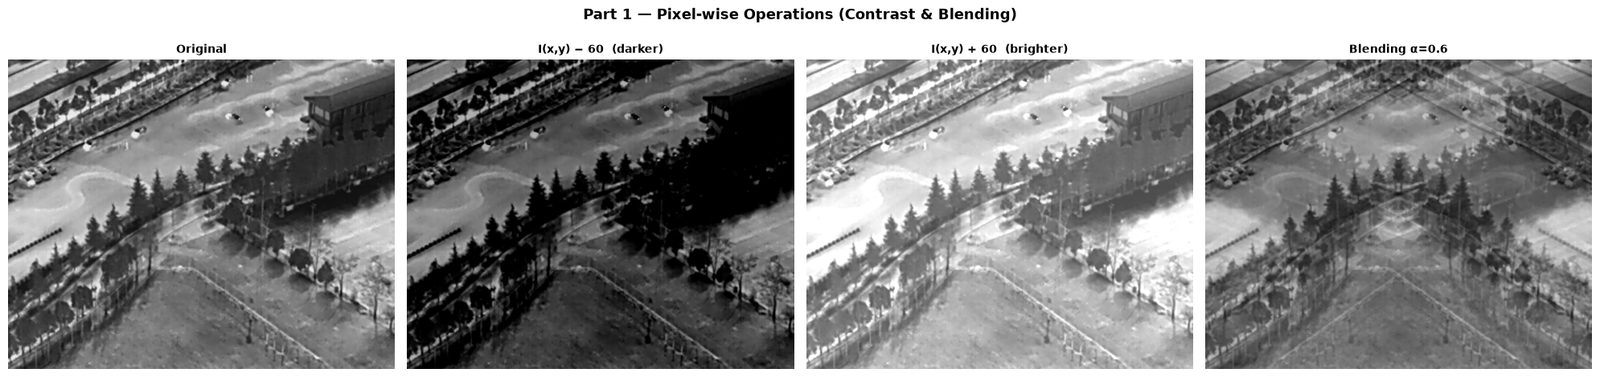


── Averaging Kernel (3×3) ──
[[0.111 0.111 0.111]
 [0.111 0.111 0.111]
 [0.111 0.111 0.111]]

── Laplacian Kernel (3×3) ──
[[ 0.  1.  0.]
 [ 1. -4.  1.]
 [ 0.  1.  0.]]

Manual convolution [101,101]: 108.89
cv2.filter2D       [101,101]: 109.00


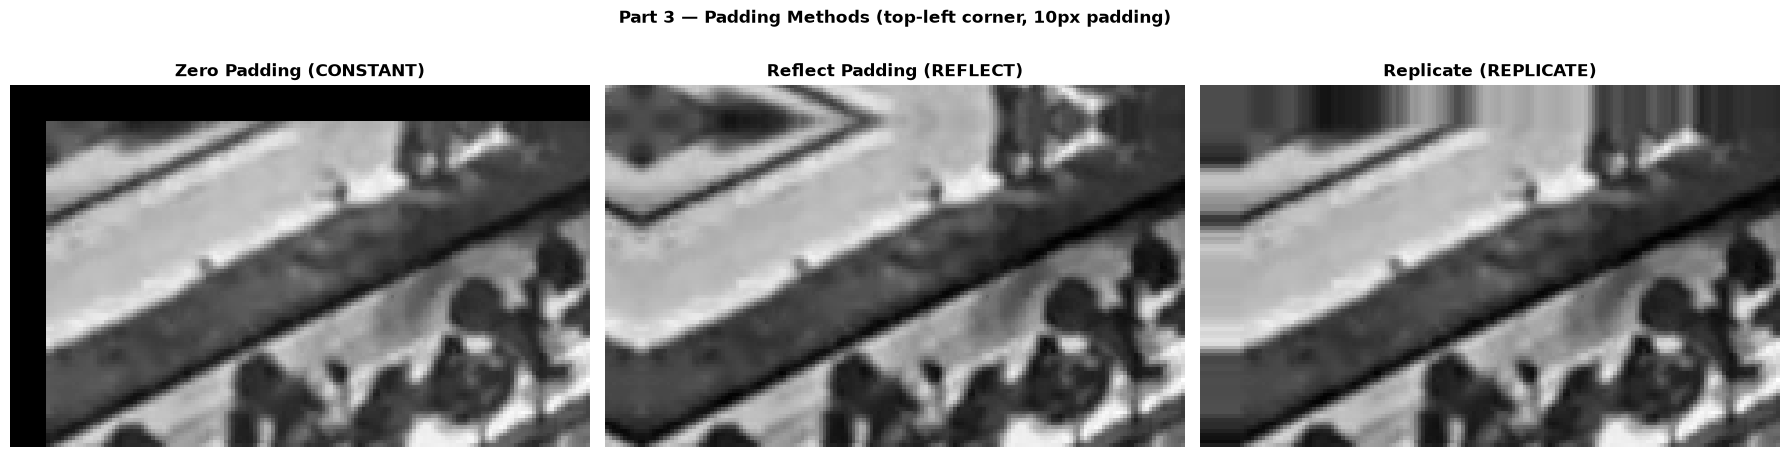

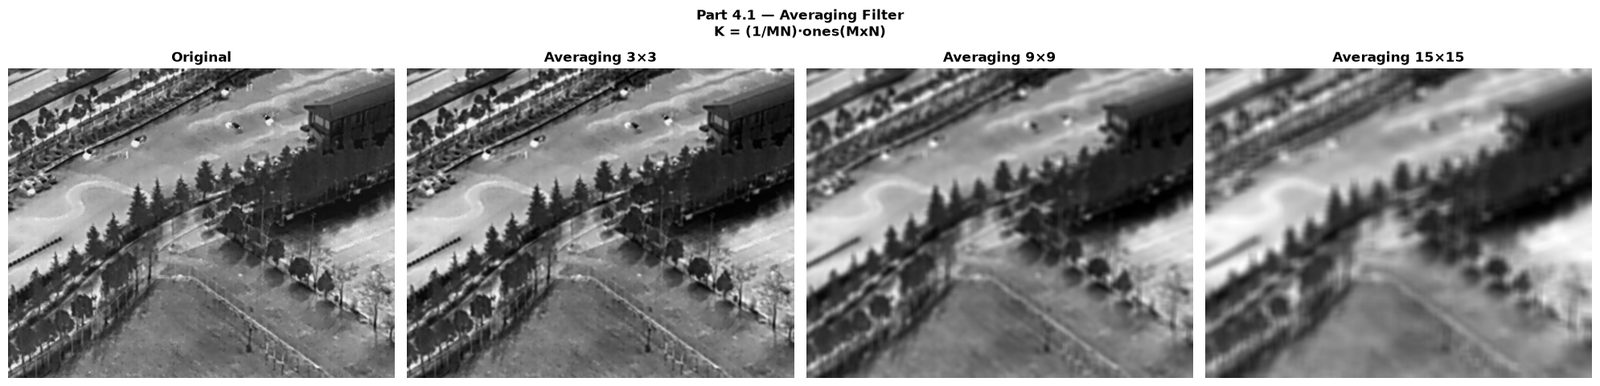

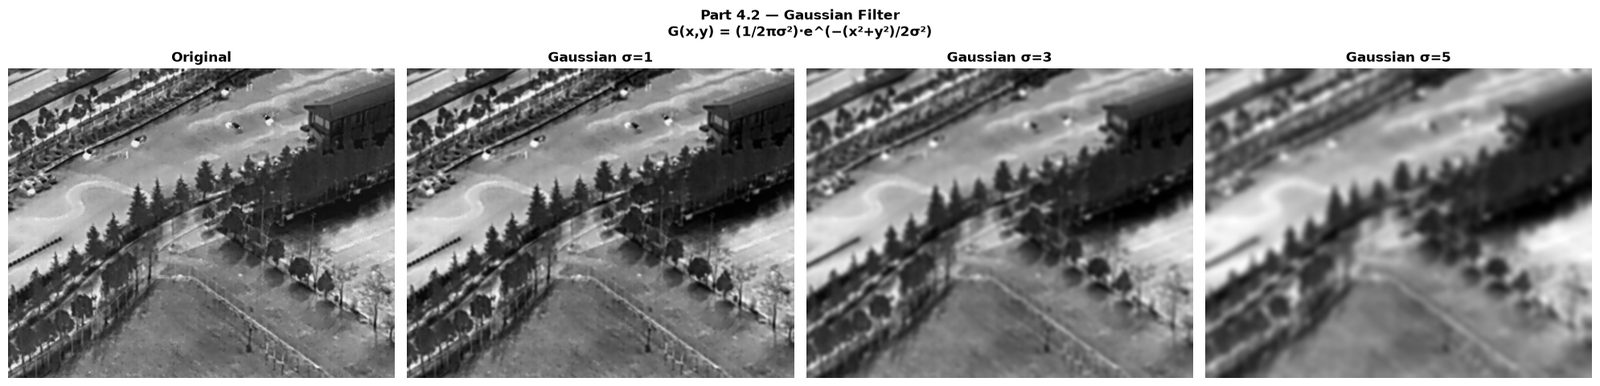

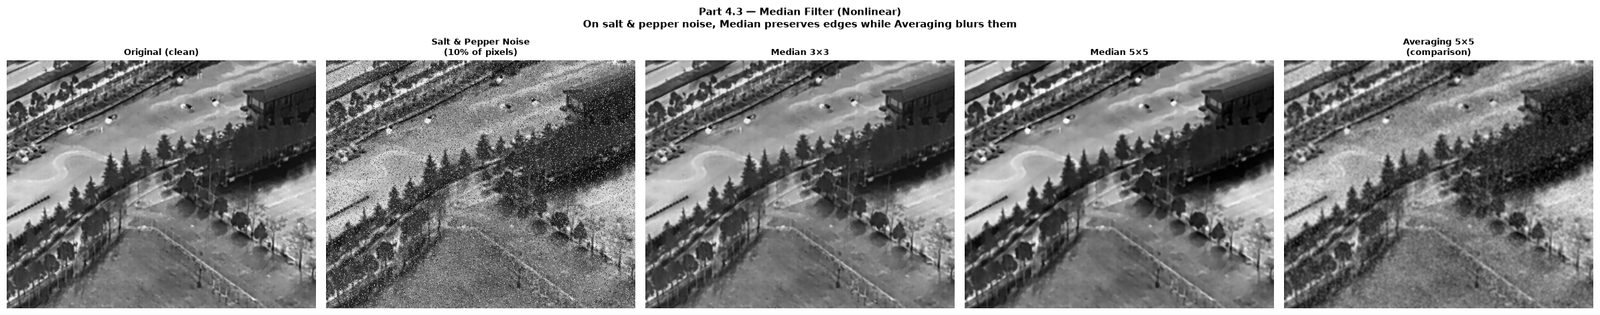

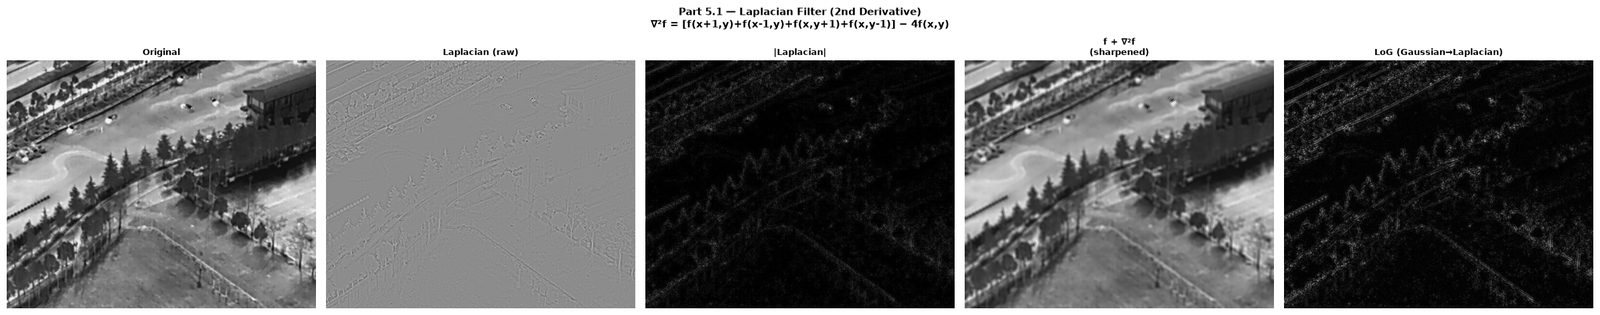

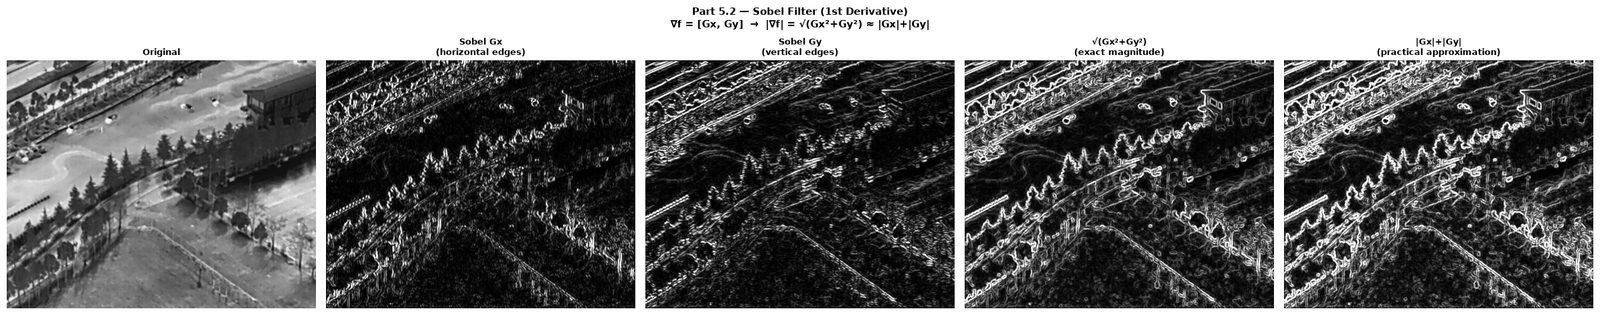

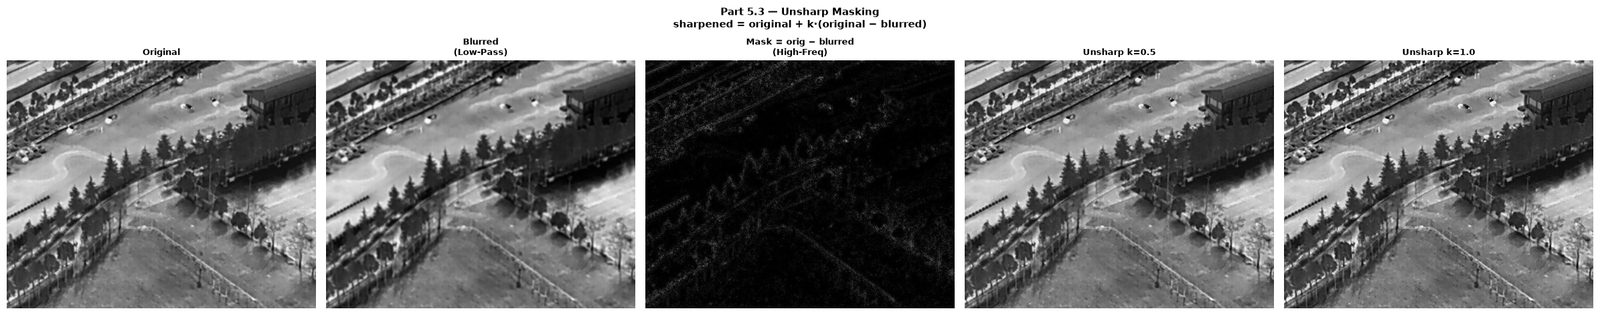

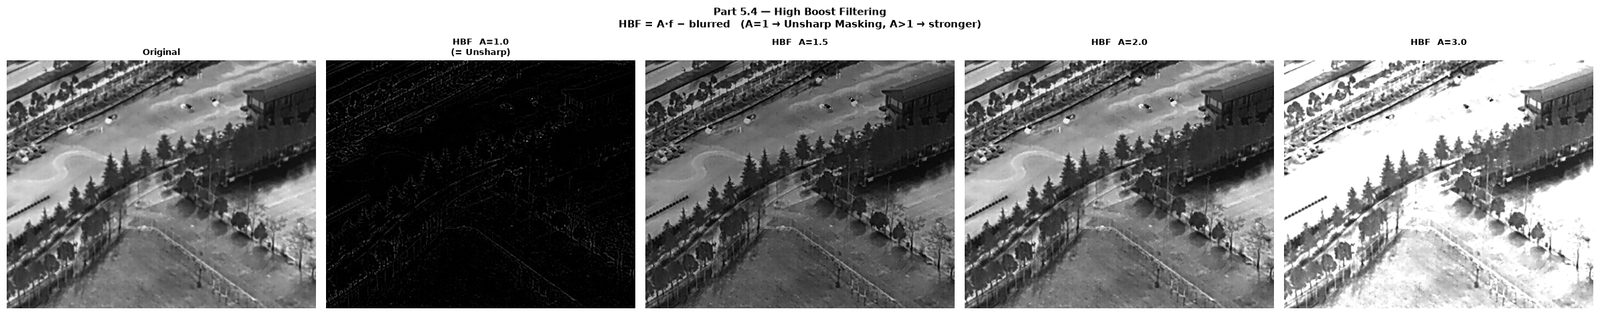

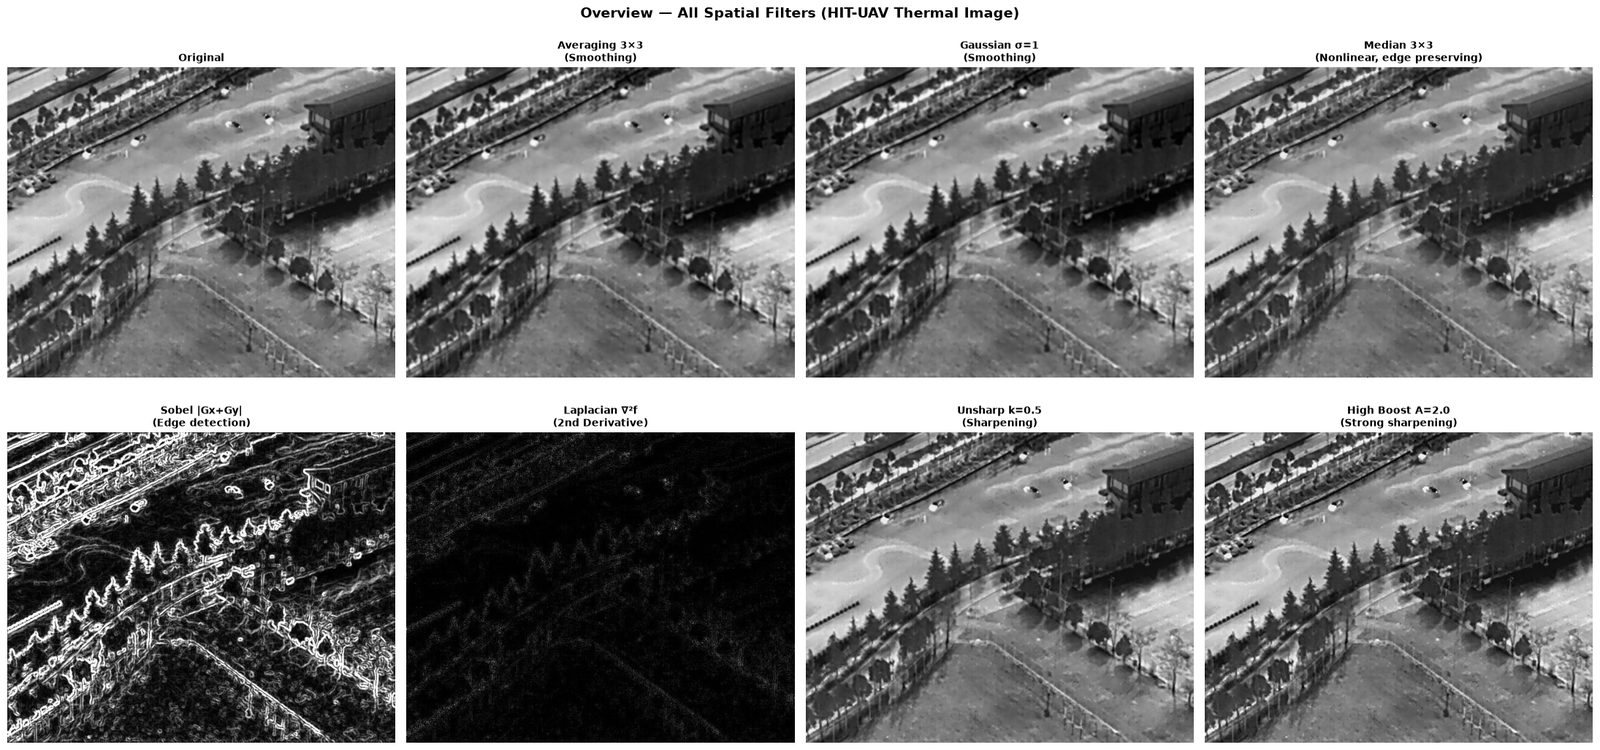


Image: 0_100_30_0_03280.jpg


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

# ── Load a sample thermal image ───────────────────────────────────────────────
sample_path = sorted(glob.glob(os.path.join(DATA_ROOT, 'hit-uav', 'images', 'train', '*.jpg')))[0]
img_bgr  = cv2.imread(sample_path)
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
print(f"Image: {os.path.basename(sample_path)}  |  Shape: {img_gray.shape}  |  Range: [{img_gray.min()}, {img_gray.max()}]")

# ══════════════════════════════════════════════════════════════════════════════
# PART 1 — Pixel-wise Operations
# I_out(x,y) = I_A(x,y) ± C   (contrast/brightness adjustment)
#          I_out = α·I_A + (1-α)·I_B   (blending)
# ══════════════════════════════════════════════════════════════════════════════
bright  = np.clip(img_gray.astype(np.int16) + 60, 0, 255).astype(np.uint8)
dark    = np.clip(img_gray.astype(np.int16) - 60, 0, 255).astype(np.uint8)
blended = cv2.addWeighted(img_gray, 0.6, cv2.flip(img_gray, 1), 0.4, 0)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, img, title in zip(axes,
    [img_gray, dark, bright, blended],
    ['Original', 'I(x,y) − 60  (darker)', 'I(x,y) + 60  (brighter)', 'Blending α=0.6']):
    ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title, fontweight='bold', fontsize=10)
    ax.axis('off')
plt.suptitle('Part 1 — Pixel-wise Operations (Contrast & Blending)', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# PART 2 — Spatial Filtering Formula: Convolution Demo
# g(x,y) = ΣΣ w(s,t)·f(x+s, y+t)
# ══════════════════════════════════════════════════════════════════════════════
# Show 3 different kernels: Averaging / Gaussian / Laplacian
kernel_avg = np.ones((3, 3), np.float32) / 9.0
kernel_lap = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], np.float32)

print("\n── Averaging Kernel (3×3) ──")
print(np.round(kernel_avg, 3))
print("\n── Laplacian Kernel (3×3) ──")
print(kernel_lap)

# Manual convolution example — on a small patch
patch = img_gray[100:103, 100:103].astype(np.float32)
result_manual = float(np.sum(kernel_avg * patch))
result_cv2    = cv2.filter2D(img_gray, -1, kernel_avg)[101, 101]
print(f"\nManual convolution [101,101]: {result_manual:.2f}")
print(f"cv2.filter2D       [101,101]: {float(result_cv2):.2f}")

# ══════════════════════════════════════════════════════════════════════════════
# PART 3 — Padding Methods
# ══════════════════════════════════════════════════════════════════════════════
pad_reflect = cv2.copyMakeBorder(img_gray, 10, 10, 10, 10, cv2.BORDER_REFLECT)
pad_const   = cv2.copyMakeBorder(img_gray, 10, 10, 10, 10, cv2.BORDER_CONSTANT, value=0)
pad_replicate = cv2.copyMakeBorder(img_gray, 10, 10, 10, 10, cv2.BORDER_REPLICATE)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, img, title in zip(axes,
    [pad_const[:100, :160], pad_reflect[:100, :160], pad_replicate[:100, :160]],
    ['Zero Padding (CONSTANT)', 'Reflect Padding (REFLECT)', 'Replicate (REPLICATE)']):
    ax.imshow(img, cmap='gray'); ax.set_title(title, fontweight='bold'); ax.axis('off')
plt.suptitle('Part 3 — Padding Methods (top-left corner, 10px padding)', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# PART 4 — Smoothing Filters
# ══════════════════════════════════════════════════════════════════════════════

# 4.1 — Averaging Filter  K = (1/9)·ones(3x3)
avg3  = cv2.blur(img_gray, (3, 3))
avg9  = cv2.blur(img_gray, (9, 9))
avg15 = cv2.blur(img_gray, (15, 15))

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, img, title in zip(axes,
    [img_gray, avg3, avg9, avg15],
    ['Original', 'Averaging 3×3', 'Averaging 9×9', 'Averaging 15×15']):
    ax.imshow(img, cmap='gray'); ax.set_title(title, fontweight='bold'); ax.axis('off')
plt.suptitle('Part 4.1 — Averaging Filter\nK = (1/MN)·ones(MxN)', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

# 4.2 — Gaussian Filter  G(x,y) = (1/2πσ²)·e^(-(x²+y²)/2σ²)
gauss_s1 = cv2.GaussianBlur(img_gray, (5, 5), 1)
gauss_s3 = cv2.GaussianBlur(img_gray, (11, 11), 3)
gauss_s5 = cv2.GaussianBlur(img_gray, (19, 19), 5)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, img, title in zip(axes,
    [img_gray, gauss_s1, gauss_s3, gauss_s5],
    ['Original', 'Gaussian σ=1', 'Gaussian σ=3', 'Gaussian σ=5']):
    ax.imshow(img, cmap='gray'); ax.set_title(title, fontweight='bold'); ax.axis('off')
plt.suptitle('Part 4.2 — Gaussian Filter\nG(x,y) = (1/2πσ²)·e^(−(x²+y²)/2σ²)', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

# 4.3 — Median Filter — Salt & Pepper noise test
rng = np.random.default_rng(42)
noise = rng.random(img_gray.shape)
sp_noisy = img_gray.copy()
sp_noisy[noise < 0.05]  = 0    # pepper
sp_noisy[noise > 0.95]  = 255  # salt

med3   = cv2.medianBlur(sp_noisy, 3)
med5   = cv2.medianBlur(sp_noisy, 5)
avg_sp = cv2.blur(sp_noisy, (5, 5))  # comparison: what does averaging do with the same noise?

fig, axes = plt.subplots(1, 5, figsize=(24, 5))
for ax, img, title in zip(axes,
    [img_gray, sp_noisy, med3, med5, avg_sp],
    ['Original (clean)', 'Salt & Pepper Noise\n(10% of pixels)', 'Median 3×3', 'Median 5×5', 'Averaging 5×5\n(comparison)']):
    ax.imshow(img, cmap='gray'); ax.set_title(title, fontweight='bold', fontsize=9); ax.axis('off')
plt.suptitle('Part 4.3 — Median Filter (Nonlinear)\nOn salt & pepper noise, Median preserves edges while Averaging blurs them', fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# PART 5 — Sharpening Filters
# ══════════════════════════════════════════════════════════════════════════════

# 5.1 — Laplacian (2nd-Order Derivative)
# ∇²f = [f(x+1,y)+f(x-1,y)+f(x,y+1)+f(x,y-1)] - 4f(x,y)
lap_raw = cv2.Laplacian(img_gray, cv2.CV_64F)
lap_abs = cv2.convertScaleAbs(lap_raw)
lap_sharp = np.clip(img_gray.astype(np.float64) + lap_raw, 0, 255).astype(np.uint8)
# LoG: Gaussian first, then Laplacian (more robust to noise)
log_blur  = cv2.GaussianBlur(img_gray, (5, 5), 1)
log_result = cv2.convertScaleAbs(cv2.Laplacian(log_blur, cv2.CV_64F))

fig, axes = plt.subplots(1, 5, figsize=(24, 5))
for ax, img, title in zip(axes,
    [img_gray, lap_raw, lap_abs, lap_sharp, log_result],
    ['Original', 'Laplacian (raw)', '|Laplacian|', 'f + ∇²f\n(sharpened)', 'LoG (Gaussian→Laplacian)']):
    ax.imshow(img, cmap='gray'); ax.set_title(title, fontweight='bold', fontsize=9); ax.axis('off')
plt.suptitle('Part 5.1 — Laplacian Filter (2nd Derivative)\n∇²f = [f(x+1,y)+f(x-1,y)+f(x,y+1)+f(x,y-1)] − 4f(x,y)', fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

# 5.2 — Sobel Filter (1st-Order Derivative / Gradient)
# ∇f ≈ |Gx| + |Gy|
sobelx = cv2.Sobel(img_gray, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(img_gray, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag_exact  = cv2.convertScaleAbs(np.sqrt(sobelx**2 + sobely**2))
sobel_mag_approx = cv2.convertScaleAbs(np.abs(sobelx) + np.abs(sobely))

fig, axes = plt.subplots(1, 5, figsize=(24, 5))
for ax, img, title in zip(axes,
    [img_gray, cv2.convertScaleAbs(sobelx), cv2.convertScaleAbs(sobely), sobel_mag_exact, sobel_mag_approx],
    ['Original', 'Sobel Gx\n(horizontal edges)', 'Sobel Gy\n(vertical edges)', '√(Gx²+Gy²)\n(exact magnitude)', '|Gx|+|Gy|\n(practical approximation)']):
    ax.imshow(img, cmap='gray'); ax.set_title(title, fontweight='bold', fontsize=9); ax.axis('off')
plt.suptitle('Part 5.2 — Sobel Filter (1st Derivative)\n∇f = [Gx, Gy]  →  |∇f| = √(Gx²+Gy²) ≈ |Gx|+|Gy|', fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

# 5.3 — Unsharp Masking
# mask = original - blurred
# sharpened = original + k*mask = (1+k)*original - k*blurred
blurred_um = cv2.GaussianBlur(img_gray, (5, 5), 0)
mask_um    = img_gray.astype(np.float64) - blurred_um.astype(np.float64)
mask_vis   = cv2.convertScaleAbs(mask_um)

unsharp_k05 = np.clip(img_gray.astype(np.float64) + 0.5 * mask_um, 0, 255).astype(np.uint8)
unsharp_k10 = np.clip(img_gray.astype(np.float64) + 1.0 * mask_um, 0, 255).astype(np.uint8)
unsharp_k15 = np.clip(img_gray.astype(np.float64) + 1.5 * mask_um, 0, 255).astype(np.uint8)

fig, axes = plt.subplots(1, 5, figsize=(24, 5))
for ax, img, title in zip(axes,
    [img_gray, blurred_um, mask_vis, unsharp_k05, unsharp_k10],
    ['Original', 'Blurred\n(Low-Pass)', 'Mask = orig − blurred\n(High-Freq)', 'Unsharp k=0.5', 'Unsharp k=1.0']):
    ax.imshow(img, cmap='gray'); ax.set_title(title, fontweight='bold', fontsize=9); ax.axis('off')
plt.suptitle('Part 5.3 — Unsharp Masking\nsharpened = original + k·(original − blurred)', fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

# 5.4 — High Boost Filtering
# HBF = A·f − blurred  =  (A-1)·f + (f - blurred)
# A=1 → Unsharp Masking, A>1 → Stronger sharpening
blurred_hb = cv2.GaussianBlur(img_gray, (5, 5), 0)

hbf_results = {}
for A in [1.0, 1.5, 2.0, 3.0]:
    hbf = np.clip(
        A * img_gray.astype(np.float64) - blurred_hb.astype(np.float64),
        0, 255
    ).astype(np.uint8)
    hbf_results[A] = hbf

fig, axes = plt.subplots(1, 5, figsize=(24, 5))
for ax, (A, img), title in zip(axes,
    [(None, img_gray)] + list(hbf_results.items()),
    ['Original'] + [f'HBF  A={A}\n{"(= Unsharp)" if A==1.0 else ""}' for A in hbf_results]):
    ax.imshow(img, cmap='gray'); ax.set_title(title, fontweight='bold', fontsize=9); ax.axis('off')
plt.suptitle('Part 5.4 — High Boost Filtering\nHBF = A·f − blurred   (A=1 → Unsharp Masking, A>1 → stronger)', fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# PART 6 — Comparison of All Filters (Overview)
# ══════════════════════════════════════════════════════════════════════════════
all_titles = [
    'Original',
    'Averaging 3×3\n(Smoothing)',
    'Gaussian σ=1\n(Smoothing)',
    'Median 3×3\n(Nonlinear, edge preserving)',
    'Sobel |Gx+Gy|\n(Edge detection)',
    'Laplacian ∇²f\n(2nd Derivative)',
    'Unsharp k=0.5\n(Sharpening)',
    'High Boost A=2.0\n(Strong sharpening)',
]
all_images = [img_gray, avg3, gauss_s1, med3, sobel_mag_approx,
              lap_abs, unsharp_k05, hbf_results[2.0]]

fig, axes = plt.subplots(2, 4, figsize=(22, 11))
axes = axes.flatten()
for ax, title, image in zip(axes, all_titles, all_images):
    ax.imshow(image, cmap='gray')
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.axis('off')
plt.suptitle('Overview — All Spatial Filters (HIT-UAV Thermal Image)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
print(f"\nImage: {os.path.basename(sample_path)}")


HIT-UAV Dataset — Basic Statistics
  train   : 2008 images  |  17628 objects  |  avg. 8.8 objects/image
  val     :  287 images  |   2460 objects  |  avg. 8.6 objects/image
  test    :  571 images  |   4811 objects  |  avg. 8.4 objects/image

  TOTAL   : 2866 images  |  24899 objects

  Class Distribution (class_ids found: [0, 1, 2, 3, 4]):
    [0] Person              : 12312  ( 49.4%)  ████████████████████████
    [1] Car                 :  7311  ( 29.4%)  ██████████████
    [2] Motorcycle          :  4980  ( 20.0%)  ██████████
    [3] Other Vehicle       :   148  (  0.6%)  
    [4] DontCare            :   148  (  0.6%)  

  Bounding Box Size (normalized [0,1]):
    Width  — mean: 0.045  std: 0.038  min: 0.005  max: 0.473
    Height — mean: 0.062  std: 0.044  min: 0.008  max: 0.361


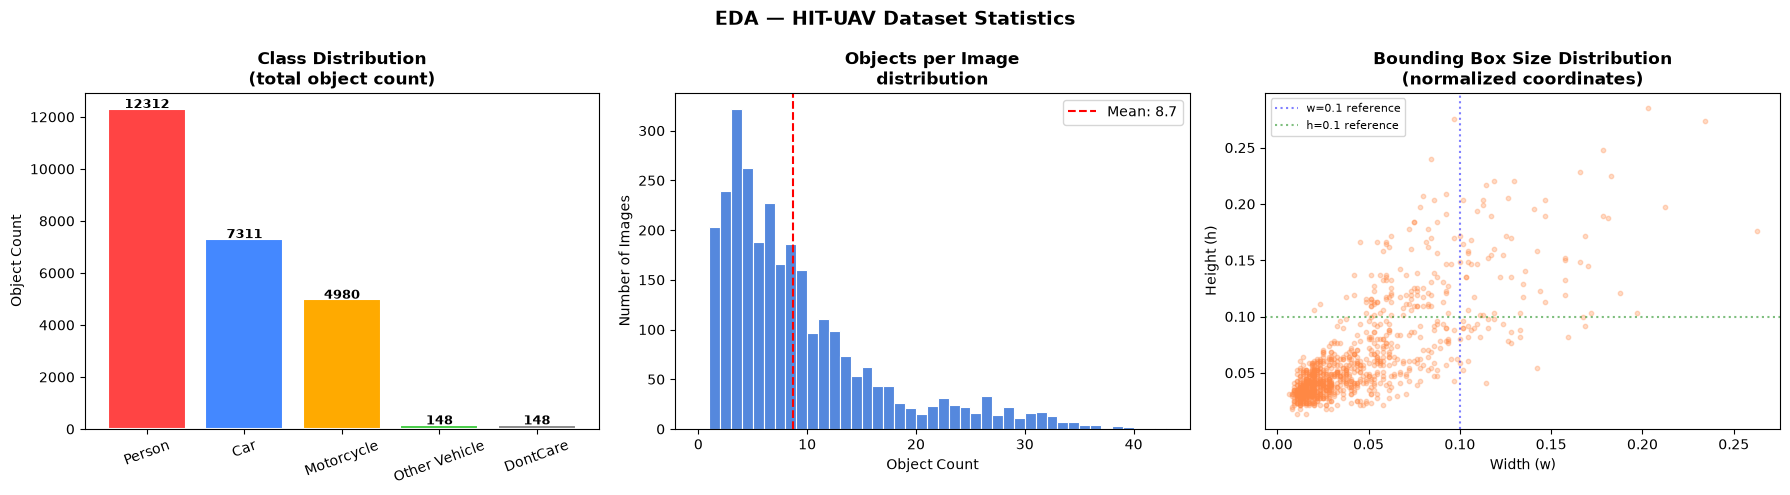

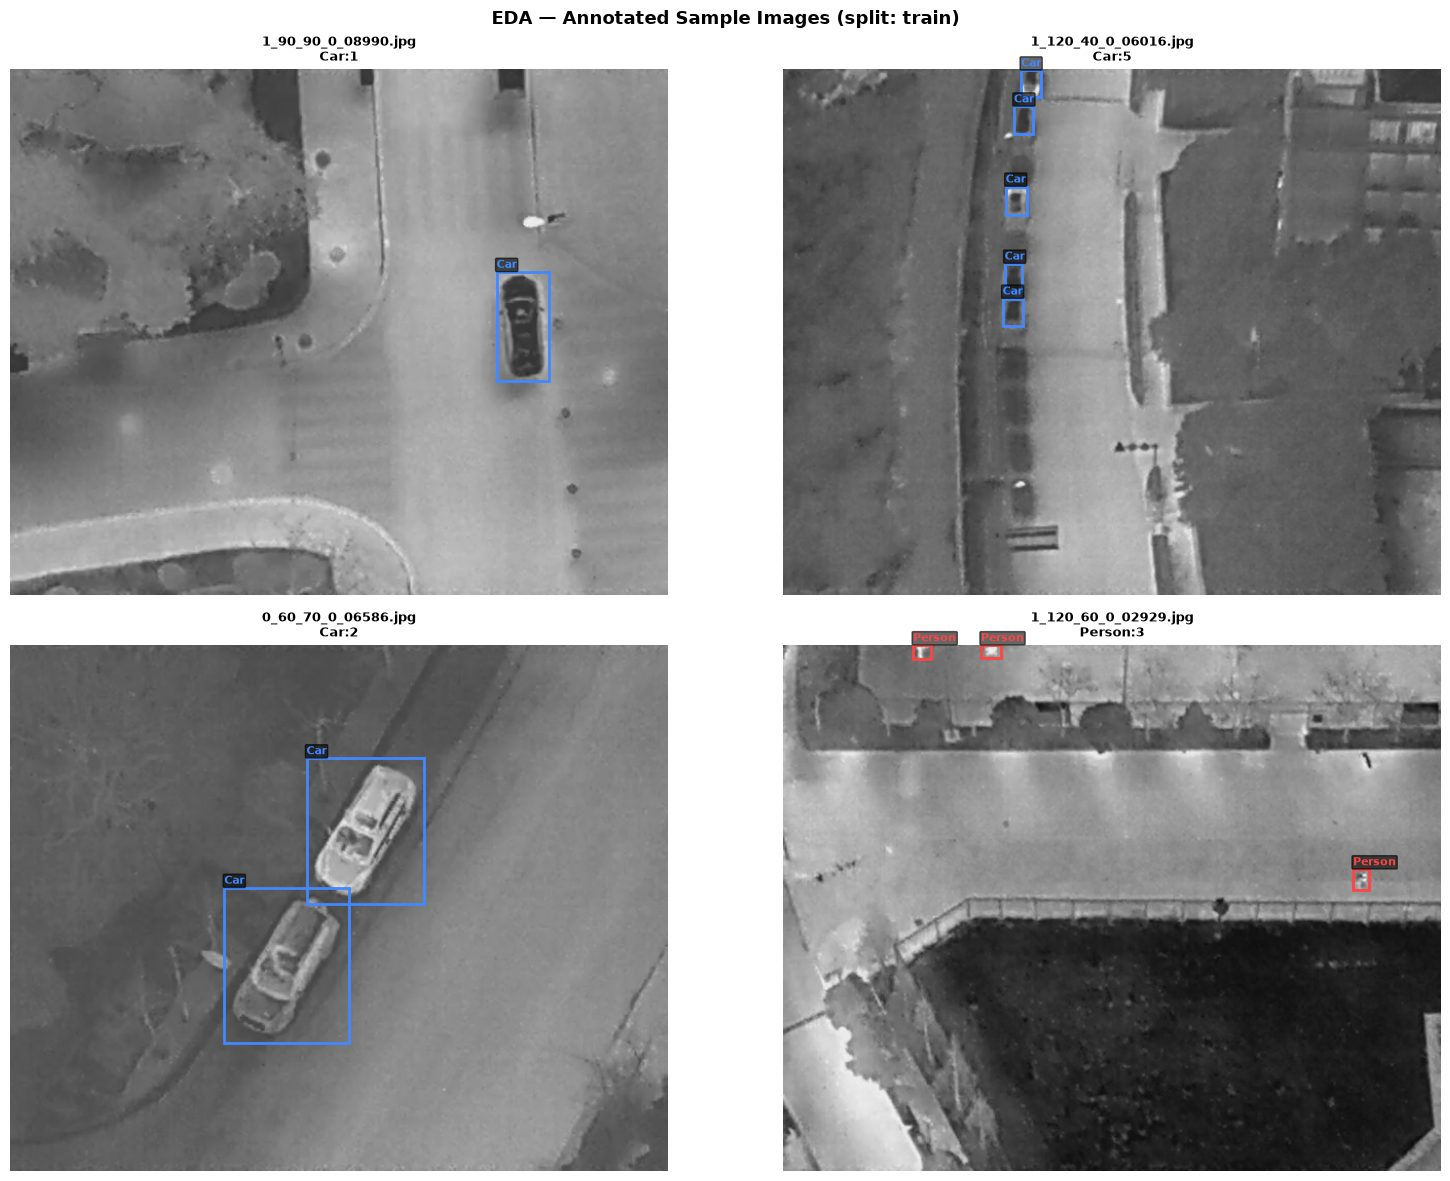

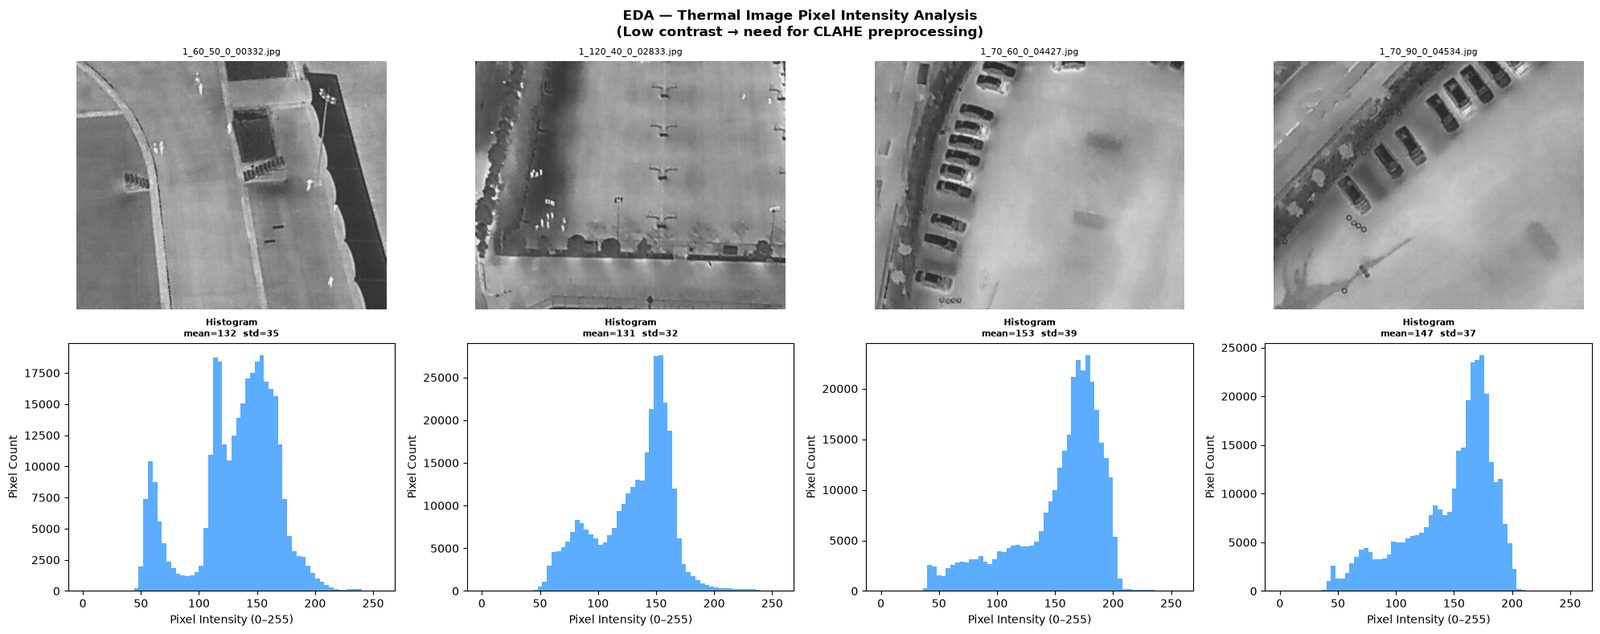


✓ EDA complete. Proceed to Section 3.3 for the preprocessing pipeline.


In [3]:
"""
EDA — Exploratory Data Analysis
Understanding the statistical structure of the dataset.
"""
import cv2
import os
import glob
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from collections import Counter, defaultdict

random.seed(42)

# ── Constants ─────────────────────────────────────────────────────────────────
BASE_DIR     = os.path.join(DATA_ROOT, 'hit-uav')
# Class 4 (DontCare) marks ambiguous regions — it is dropped during preprocessing
CLASSES      = {0: 'Person', 1: 'Car', 2: 'Motorcycle', 3: 'Other Vehicle', 4: 'DontCare'}
CLASS_COLORS = {0: '#FF4444', 1: '#4488FF', 2: '#FFAA00', 3: '#44CC44', 4: '#888888'}
SPLITS       = ['train', 'val', 'test']

def class_name(cls_id):
    return CLASSES.get(cls_id, f'Unknown-{cls_id}')

def class_color(cls_id):
    return CLASS_COLORS.get(cls_id, '#AAAAAA')

# ══════════════════════════════════════════════════════════════════════════════
# STEP 1 — Basic Dataset Statistics
# ══════════════════════════════════════════════════════════════════════════════
print("=" * 60)
print("HIT-UAV Dataset — Basic Statistics")
print("=" * 60)

total_images  = 0
total_objects = 0
class_counts  = Counter()
obj_per_image = []
bbox_widths   = []
bbox_heights  = []

for split in SPLITS:
    img_dir = os.path.join(BASE_DIR, 'images', split)
    imgs    = glob.glob(os.path.join(img_dir, '*.jpg'))

    split_images  = len(imgs)
    split_objects = 0

    for img_path in imgs:
        lbl_path = img_path.replace('images', 'labels').replace('.jpg', '.txt')
        n_obj = 0
        if os.path.exists(lbl_path):
            with open(lbl_path) as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        cls_id = int(float(parts[0]))
                        w, h   = float(parts[3]), float(parts[4])
                        class_counts[cls_id] += 1
                        bbox_widths.append(w)
                        bbox_heights.append(h)
                        split_objects += 1
                        n_obj += 1
        obj_per_image.append(n_obj)

    total_images  += split_images
    total_objects += split_objects
    print(f"  {split:8s}: {split_images:4d} images  |  {split_objects:5d} objects  |  "
          f"avg. {split_objects/max(split_images,1):.1f} objects/image")

print(f"\n  TOTAL   : {total_images:4d} images  |  {total_objects:5d} objects")

# Show all class IDs found (including unknown ones)
print(f"\n  Class Distribution (class_ids found: {sorted(class_counts.keys())}):")
for cls_id, count in sorted(class_counts.items()):
    pct = 100 * count / total_objects
    bar = '█' * int(pct / 2)
    print(f"    [{cls_id}] {class_name(cls_id):20s}: {count:5d}  ({pct:5.1f}%)  {bar}")

print(f"\n  Bounding Box Size (normalized [0,1]):")
print(f"    Width  — mean: {np.mean(bbox_widths):.3f}  std: {np.std(bbox_widths):.3f}  "
      f"min: {np.min(bbox_widths):.3f}  max: {np.max(bbox_widths):.3f}")
print(f"    Height — mean: {np.mean(bbox_heights):.3f}  std: {np.std(bbox_heights):.3f}  "
      f"min: {np.min(bbox_heights):.3f}  max: {np.max(bbox_heights):.3f}")

# ══════════════════════════════════════════════════════════════════════════════
# STEP 2 — Visual Statistics Panel
# ══════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 2a. Class distribution bar chart
cls_ids    = sorted(class_counts.keys())
cls_names  = [class_name(i) for i in cls_ids]
cls_values = [class_counts[i] for i in cls_ids]
bars = axes[0].bar(cls_names, cls_values,
                   color=[class_color(i) for i in cls_ids],
                   edgecolor='white', linewidth=1.5)
axes[0].set_title('Class Distribution\n(total object count)', fontweight='bold')
axes[0].set_ylabel('Object Count')
axes[0].tick_params(axis='x', rotation=20)
for bar, val in zip(bars, cls_values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
                 str(val), ha='center', fontweight='bold', fontsize=9)

# 2b. Objects-per-image histogram
max_obj = max(obj_per_image) if obj_per_image else 10
axes[1].hist(obj_per_image, bins=range(0, max_obj + 2), color='#5588DD',
             edgecolor='white', linewidth=0.8)
axes[1].set_title('Objects per Image\ndistribution', fontweight='bold')
axes[1].set_xlabel('Object Count')
axes[1].set_ylabel('Number of Images')
axes[1].axvline(np.mean(obj_per_image), color='red', linestyle='--',
                label=f'Mean: {np.mean(obj_per_image):.1f}')
axes[1].legend()

# 2c. Bounding box size distribution (scatter)
n_sample   = min(1000, len(bbox_widths))
sample_idx = random.sample(range(len(bbox_widths)), n_sample)
w_sample   = [bbox_widths[i]  for i in sample_idx]
h_sample   = [bbox_heights[i] for i in sample_idx]
axes[2].scatter(w_sample, h_sample, alpha=0.3, s=10, color='#FF8844')
axes[2].set_title('Bounding Box Size Distribution\n(normalized coordinates)', fontweight='bold')
axes[2].set_xlabel('Width (w)')
axes[2].set_ylabel('Height (h)')
axes[2].axvline(0.1, color='blue',  linestyle=':', alpha=0.5, label='w=0.1 reference')
axes[2].axhline(0.1, color='green', linestyle=':', alpha=0.5, label='h=0.1 reference')
axes[2].legend(fontsize=8)

plt.suptitle('EDA — HIT-UAV Dataset Statistics', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# STEP 3 — Annotated Sample Image Visualization
# ══════════════════════════════════════════════════════════════════════════════
def visualize_annotated_samples(n=4, split='train'):
    img_dir   = os.path.join(BASE_DIR, 'images', split)
    img_paths = glob.glob(os.path.join(img_dir, '*.jpg'))
    samples   = random.sample(img_paths, min(n, len(img_paths)))

    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    axes = axes.flatten()

    for ax, img_path in zip(axes, samples):
        img     = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        H, W    = img.shape[:2]
        ax.imshow(img_rgb)

        lbl_path   = img_path.replace('images', 'labels').replace('.jpg', '.txt')
        obj_counts = Counter()

        if os.path.exists(lbl_path):
            with open(lbl_path) as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) < 5:
                        continue
                    cls_id        = int(float(parts[0]))
                    xc, yc, bw, bh = [float(x) for x in parts[1:5]]
                    x_min = (xc - bw/2) * W
                    y_min = (yc - bh/2) * H
                    pw, ph = bw * W, bh * H
                    color  = class_color(cls_id)
                    rect   = patches.Rectangle((x_min, y_min), pw, ph,
                                               linewidth=2, edgecolor=color, facecolor='none')
                    ax.add_patch(rect)
                    ax.text(x_min, y_min - 4, class_name(cls_id),
                            color=color, fontsize=8, fontweight='bold',
                            bbox=dict(boxstyle='round,pad=0.1', facecolor='black', alpha=0.6))
                    obj_counts[cls_id] += 1

        subtitle = '  '.join([f"{class_name(k)}:{v}" for k, v in obj_counts.items()])
        ax.set_title(f'{os.path.basename(img_path)}\n{subtitle}', fontsize=9, fontweight='bold')
        ax.axis('off')

    plt.suptitle(f'EDA — Annotated Sample Images (split: {split})',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

visualize_annotated_samples(n=4, split='train')

# ══════════════════════════════════════════════════════════════════════════════
# STEP 4 — Thermal Image Pixel Intensity (Histogram) Analysis
# ══════════════════════════════════════════════════════════════════════════════
img_dir  = os.path.join(BASE_DIR, 'images', 'train')
all_imgs = glob.glob(os.path.join(img_dir, '*.jpg'))
sample_4 = random.sample(all_imgs, min(4, len(all_imgs)))

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for col, img_path in enumerate(sample_4):
    img_gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    axes[0][col].imshow(img_gray, cmap='gray', vmin=0, vmax=255)
    axes[0][col].set_title(os.path.basename(img_path)[:22], fontsize=8)
    axes[0][col].axis('off')
    axes[1][col].hist(img_gray.ravel(), bins=64, range=(0, 256),
                      color='#3399FF', edgecolor='none', alpha=0.8)
    axes[1][col].set_title(f'Histogram\nmean={img_gray.mean():.0f}  std={img_gray.std():.0f}',
                           fontsize=8, fontweight='bold')
    axes[1][col].set_xlabel('Pixel Intensity (0–255)')
    axes[1][col].set_ylabel('Pixel Count')

plt.suptitle('EDA — Thermal Image Pixel Intensity Analysis\n'
             '(Low contrast → need for CLAHE preprocessing)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
print("\n✓ EDA complete. Proceed to Section 3.3 for the preprocessing pipeline.")


## Section 3.3 — Thermal Image Preprocessing Pipeline

### Why Is Preprocessing Needed?

The thermal image histograms we saw in the EDA showed low contrast and sensor noise.
To give YOLOv8's convolutional layers **cleaner input**, we apply a 3-stage pipeline:

```
Raw Thermal Image
       │
  [1] Median Filter (3×3)        ← Nonlinear — removes salt & pepper noise, preserves edges
       │                            (median filter = edge-preserving nonlinear operator)
  [2] CLAHE                      ← Adaptive Histogram Equalization — improves local contrast
       │                            clipLimit=2.0, tileGridSize=8×8
  [3] Unsharp Masking (k=0.5)    ← Linear — sharpens object edges
       │                            sharpened = (1+k)·img − k·blurred
       ↓
Processed Image → dataset/hit-uav-processed/
```

### Pipeline Decisions

| Step | Filter | Parameter | Why? |
|---|---|---|---|
| 1 | Median | kernel=3×3 | Sensor noise is salt & pepper type → median is optimal |
| 2 | CLAHE | clip=2.0, tile=8×8 | Global equalization distorts bright regions → local CLAHE |
| 3 | Unsharp | k=0.5 | k=1.0 amplifies noise, k=0.5 is balanced |

> **Note:** Box coordinates are copied **unchanged** — they are normalized to the original image size, and preprocessing does not change the geometry.
> The only label change: boxes of class **4 (`DontCare`)** are removed. They mark ambiguous regions and are not one of our 4 target classes (YOLO would reject them as `class 4 exceeds nc=4`).

<repo>/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


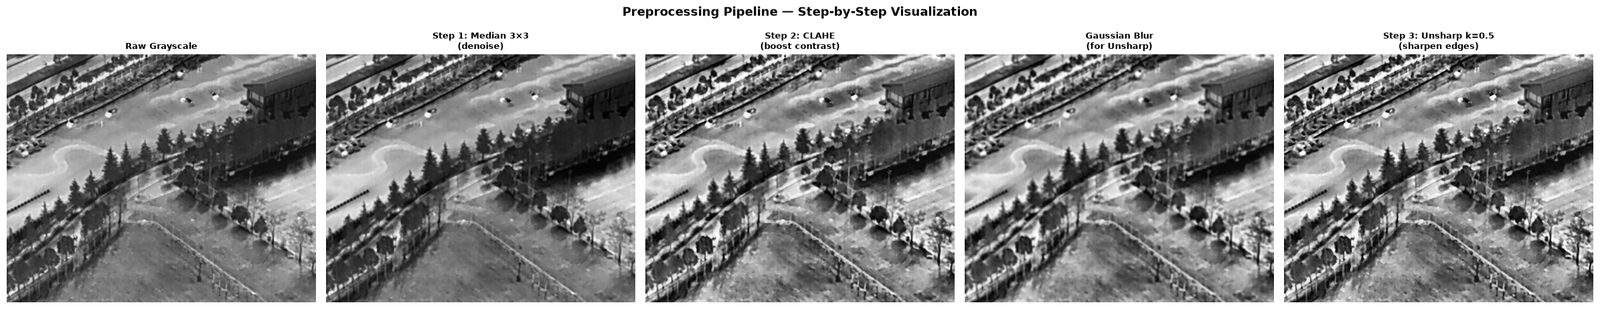


  train   : processing 2008 images...



  val     : processing 287 images...



  test    : processing 571 images...



✓ Preprocessing complete: 2866 images → <repo>/dataset/hit-uav-processed
  DontCare boxes removed: 148


In [4]:
import cv2
import os
import glob
import shutil
from tqdm.auto import tqdm

SRC_BASE  = os.path.join(DATA_ROOT, 'hit-uav')
DST_BASE  = os.path.join(DATA_ROOT, 'hit-uav-processed')
SPLITS    = ['train', 'val', 'test']
NUM_CLASSES = 4  # 0 Person, 1 Car, 2 Motorcycle, 3 Other Vehicle (4 = DontCare is dropped)

def preprocess_thermal(img_bgr):
    """Median(3x3) → CLAHE → Unsharp Masking(k=0.5)"""
    gray     = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    # Step 1: Median — remove salt & pepper noise (nonlinear, edge preserving)
    denoised = cv2.medianBlur(gray, 3)
    # Step 2: CLAHE — improve local contrast
    clahe    = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(denoised)
    # Step 3: Unsharp Masking — sharpen edges
    blurred  = cv2.GaussianBlur(enhanced, (5, 5), 0)
    # sharpened = (1+k)*enhanced - k*blurred = 1.5*enhanced - 0.5*blurred
    sharpened = cv2.addWeighted(enhanced, 1.5, blurred, -0.5, 0)
    return cv2.cvtColor(sharpened, cv2.COLOR_GRAY2BGR)

# ── Visualization: pipeline step by step ─────────────────────────────────────
import matplotlib.pyplot as plt
sample_imgs = sorted(glob.glob(os.path.join(SRC_BASE, 'images', 'train', '*.jpg')))
if sample_imgs:
    demo = cv2.imread(sample_imgs[0])
    gray_demo     = cv2.cvtColor(demo, cv2.COLOR_BGR2GRAY)
    med_demo      = cv2.medianBlur(gray_demo, 3)
    clahe_obj     = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    clahe_demo    = clahe_obj.apply(med_demo)
    blur_demo     = cv2.GaussianBlur(clahe_demo, (5, 5), 0)
    unsharp_demo  = cv2.addWeighted(clahe_demo, 1.5, blur_demo, -0.5, 0)

    fig, axes = plt.subplots(1, 5, figsize=(24, 5))
    for ax, img, title in zip(axes,
        [gray_demo, med_demo, clahe_demo, blur_demo, unsharp_demo],
        ['Raw Grayscale', 'Step 1: Median 3×3\n(denoise)',
         'Step 2: CLAHE\n(boost contrast)',
         'Gaussian Blur\n(for Unsharp)',
         'Step 3: Unsharp k=0.5\n(sharpen edges)']):
        ax.imshow(img, cmap='gray')
        ax.set_title(title, fontweight='bold', fontsize=9)
        ax.axis('off')
    plt.suptitle('Preprocessing Pipeline — Step-by-Step Visualization', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

# ── Apply to the whole dataset ────────────────────────────────────────────────
if os.path.exists(DST_BASE):
    shutil.rmtree(DST_BASE)
    print(f"Removed old processed folder: {DST_BASE}")

total_processed = 0
dropped_boxes   = 0
for split in SPLITS:
    src_img_dir = os.path.join(SRC_BASE, 'images', split)
    src_lbl_dir = os.path.join(SRC_BASE, 'labels', split)
    dst_img_dir = os.path.join(DST_BASE, 'images', split)
    dst_lbl_dir = os.path.join(DST_BASE, 'labels', split)

    os.makedirs(dst_img_dir, exist_ok=True)
    os.makedirs(dst_lbl_dir, exist_ok=True)

    img_paths = sorted(glob.glob(os.path.join(src_img_dir, '*.jpg')))
    print(f"\n  {split:8s}: processing {len(img_paths)} images...", flush=True)

    for img_path in tqdm(img_paths, desc=f'  {split}', leave=False):
        fname     = os.path.basename(img_path)
        dst_path  = os.path.join(dst_img_dir, fname)

        img_bgr   = cv2.imread(img_path)
        processed = preprocess_thermal(img_bgr)
        cv2.imwrite(dst_path, processed, [cv2.IMWRITE_JPEG_QUALITY, 95])

        # Copy labels — coordinates do not change, only DontCare boxes are removed
        lbl_src = os.path.join(src_lbl_dir, fname.replace('.jpg', '.txt'))
        lbl_dst = os.path.join(dst_lbl_dir, fname.replace('.jpg', '.txt'))
        kept = []
        if os.path.exists(lbl_src):
            with open(lbl_src) as f:
                for line in f:
                    parts = line.split()
                    if len(parts) >= 5 and int(float(parts[0])) < NUM_CLASSES:
                        kept.append(line.strip())
                    elif parts:
                        dropped_boxes += 1
        with open(lbl_dst, 'w') as f:  # empty file for images with no objects
            f.write('\n'.join(kept) + ('\n' if kept else ''))

        total_processed += 1

print(f"\n✓ Preprocessing complete: {total_processed} images → {DST_BASE}")
print(f"  DontCare boxes removed: {dropped_boxes}")


## Section 4 — Data Configuration for Model Training

### 4.1 Data Splitting with the Hold-Out Method

In machine learning it is standard to split the data into **three separate sets**:

```
                    All Data (2,866 images)
                           │
          ┌────────────────┼───────────────┐
          │                │               │
      70% Training     10% Validation   20% Test
        (2,008)            (287)          (571)
          │                │               │
    Model learns       Hyperparameter    Final model
    weights here       optimization      performance
```

| Set | Ratio | Purpose | How Often Is It Used? |
|---|---|---|---|
| **Train** | 70% | Learning model weights | Every epoch |
| **Validation** | 10% | Monitoring overfitting, hyperparameter selection | End of every epoch |
| **Test** | 20% | Final independent evaluation | **Only once** (at the end) |

> ⚠️ **Important:** The test set must **never** be seen during training. Otherwise "data leakage" occurs and the model looks better than it really is.

### 4.2 Why 70% / 10% / 20%?

- **Small dataset (< 10,000 samples):** 20% for testing gives enough statistical power
- **Validation is kept small:** YOLOv8 already has a built-in early stopping mechanism
- **Alternative:** k-Fold Cross Validation (k=5 or 10) is more reliable but much slower

### 4.3 YOLO Directory Structure

The folder structure YOLOv8 expects:
```
dataset/hit-uav-processed/
├── images/
│   ├── train/   ← training images (.jpg)
│   ├── val/     ← validation images
│   └── test/    ← test images
└── labels/
    ├── train/   ← training labels (.txt, YOLO format)
    ├── val/
    └── test/
```

Each image has a `.txt` label file with the same name.
For images without objects, the label file is left **empty** (not deleted).

### 4.4 YAML Configuration File

YOLOv8 recognizes the dataset through a `.yaml` file, which specifies:
- `path`: dataset root directory
- `train`, `val`, `test`: image folders (relative to path)
- `nc`: number of classes
- `names`: list of class names

In [5]:
import os
import yaml

base_path = os.path.join(DATA_ROOT, 'hit-uav-processed')
DATA_YAML = os.path.join(DATA_ROOT, 'hituav_data.yaml')

data_yaml = {
    'path': base_path,
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',
    'nc': 4,
    'names': ['Person', 'Car', 'Motorcycle', 'Other Vehicle']
}

with open(DATA_YAML, 'w') as outfile:
    yaml.dump(data_yaml, outfile, default_flow_style=False, sort_keys=False)

print(open(DATA_YAML).read())
print(f"YAML created → {DATA_YAML}")


path: <repo>/dataset/hit-uav-processed
train: images/train
val: images/val
test: images/test
nc: 4
names:
- Person
- Car
- Motorcycle
- Other Vehicle

YAML created → <repo>/dataset/hituav_data.yaml


## Section 5 — YOLOv8 Model Training

### 5.1 YOLO (You Only Look Once) Architecture

YOLO is a deep learning architecture that performs object detection in a **single pass**.

```
Input Image (640×640)
        │
   [Backbone]          ← CSP-DarkNet: feature extraction
   Conv → BN → SiLU   ← learned filters in every layer
        │
   [Neck — FPN+PAN]    ← Feature Pyramid Network: multi-scale feature fusion
        │
   [Head — Detection]  ← predictions at 3 scales (20×20, 40×40, 80×80 grid)
        │
   [Output]            ← per grid cell: [x, y, w, h, conf, cls_prob × 4]
```

**Why YOLOv8n ("nano")** was chosen:
- ~3.0M parameters (YOLOv8l: ~43M) → fast training
- Sufficient capacity for a small dataset (2,866 images)
- Suitable for real-time inference

### 5.2 Transfer Learning

```
COCO (118K images, 80 classes)
      ↓  pre-trained weights (yolov8n.pt)
HIT-UAV (2,866 images, 4 classes)
      ↓  fine-tuning
Thermal image detection model
```

**Why Transfer Learning?**
- 2,866 images are **not enough** to train from scratch
- COCO weights have learned general visual features (edges, textures, shapes)
- Thermal images share these low-level features too
- Training time is **much shorter** (50 epochs ~ 28 minutes on a T4 GPU)

### 5.3 Key Hyperparameters

| Parameter | Value | Description |
|---|---|---|
| `epochs` | 50 | Number of passes over the whole dataset |
| `imgsz` | 640 | Image resize (square) |
| `device` | auto | CUDA GPU (`0`) on Colab, `mps` on Apple Silicon, otherwise CPU |
| `batch` | auto | Automatic batch size (based on GPU memory) |
| `optimizer` | auto | Ultralytics picks SGD or AdamW based on training length |
| `lr0` | 0.01 | Initial learning rate |
| `patience` | 100 | Early stopping patience (epochs) |

### 5.4 Loss Functions

YOLOv8 uses three loss components:

```
L_total = λ_box · L_box + λ_cls · L_cls + λ_dfl · L_dfl

L_box  → CIoU Loss:  position and size prediction error
L_cls  → BCE Loss:   class probability error
L_dfl  → Distribution Focal Loss: box edge distribution prediction
```

### 5.5 What to Watch During Training

Pay attention to the following in the training output:
- `train/box_loss`, `train/cls_loss` → should decrease every epoch
- `val/box_loss`, `val/cls_loss` → should decrease; if they diverge **a lot** from the training loss, it's overfitting
- `metrics/mAP50` → should increase, target: **> 0.80**
- `metrics/mAP50-95` → a stricter metric, usually lower

> 💡 After training finishes, all plots and weights are saved under `runs/detect/train/` (repo root locally, `/content` on Colab).
> Best model: `runs/detect/train/weights/best.pt`

In [6]:
if IN_COLAB:
    !pip install -q ultralytics

import torch
from ultralytics import YOLO

if torch.cuda.is_available():
    DEVICE = 0
elif torch.backends.mps.is_available():
    DEVICE = 'mps'
else:
    DEVICE = 'cpu'
print(f"Training device: {DEVICE}")

model = YOLO('yolov8n.pt')

results = model.train(
    data=DATA_YAML,
    epochs=50,
    imgsz=640,
    device=DEVICE,
    seed=0,
    project=RUNS_DIR,
    name='train',
    exist_ok=True,
)

TRAIN_DIR = os.path.join(RUNS_DIR, 'train')
print(f"\nTraining complete. Results: {TRAIN_DIR}")


Training device: mps
Ultralytics 8.4.180 🚀 Python-3.12.8 torch-2.14.1 MPS (Apple M4)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=<repo>/dataset/hituav_data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, op

       1/50      4.23G      1.828      1.824      1.146        191        640: 100% ━━━━━━━━━━━━ 126/126 1.5it/s 1:22
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 1.8it/s 5.0s
                   all        287       2453      0.791      0.434      0.509      0.258

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/50      4.29G      1.467      1.213      1.061        121        640: 0% ──────────── 0/126  0.8s

       2/50      5.17G      1.699      1.228      1.063        139        640: 100% ━━━━━━━━━━━━ 126/126 1.7it/s 1:15
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.4it/s 3.7s
                   all        287       2453      0.727      0.442      0.499      0.262

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      4.27G       1.69      1.092      1.017        306        640: 0% ──────────── 0/126  0.6s

       3/50      5.17G      1.686      1.206      1.066        125        640: 100% ━━━━━━━━━━━━ 126/126 1.7it/s 1:13
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.4it/s 3.7s
                   all        287       2453      0.501      0.488      0.526      0.263

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50       4.3G      1.897      1.356      1.101        329        640: 0% ──────────── 0/126  0.7s

       4/50      4.29G      1.656      1.137      1.058         98        640: 100% ━━━━━━━━━━━━ 126/126 1.7it/s 1:13
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.4it/s 3.7s
                   all        287       2453      0.818      0.517       0.58      0.302

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       5/50      4.28G       1.58      1.049      1.021        240        640: 0% ──────────── 0/126  0.7s

...

      46/50      5.17G      1.204     0.5954     0.9081         85        640: 100% ━━━━━━━━━━━━ 126/126 1.8it/s 1:10
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.4it/s 3.7s
                   all        287       2453       0.89      0.841      0.878       0.57

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      47/50      4.29G     0.9664     0.5111     0.8367        109        640: 0% ──────────── 0/126  0.7s

      47/50      5.17G      1.205     0.5891     0.9067         56        640: 100% ━━━━━━━━━━━━ 126/126 1.8it/s 1:11
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.5it/s 3.6s
                   all        287       2453      0.917      0.826      0.885      0.581

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      48/50       4.3G       1.12      0.565     0.8429        104        640: 0% ──────────── 0/126  0.6s

      48/50      5.17G      1.185     0.5804     0.9027         65        640: 100% ━━━━━━━━━━━━ 126/126 1.8it/s 1:10
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.5it/s 3.7s
                   all        287       2453      0.905      0.824      0.885      0.583

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      49/50      4.29G      1.166     0.5765     0.9116        174        640: 0% ──────────── 0/126  0.7s

      49/50      4.29G      1.186     0.5797     0.9045         99        640: 100% ━━━━━━━━━━━━ 126/126 1.8it/s 1:09
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.5it/s 3.6s
                   all        287       2453      0.886      0.849      0.886      0.579

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      50/50      4.29G       1.19     0.5677     0.8913        142        640: 0% ──────────── 0/126  0.7s

      50/50      5.26G      1.181     0.5724      0.902         67        640: 100% ━━━━━━━━━━━━ 126/126 1.8it/s 1:10
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.5it/s 3.7s
                   all        287       2453      0.896      0.833      0.882      0.581

50 epochs completed in 1.085 hours.
Optimizer stripped from <repo>/runs/detect/train/weights/last.pt, 6.5MB
Optimizer stripped from <repo>/runs/detect/train/weights/best.pt, 6.5MB

Validating <repo>/runs/detect/train/weights/best.pt...
Ultralytics 8.4.180 🚀 Python-3.12.8 torch-2.14.1 MPS (Apple M4)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.5it/s 3.6s
                   all        287       2453      0.905      0.824      0.885      0.583
                Person        171       1168      0.899      0.828      0

## Section 6 — Results and Performance Evaluation

### 6.1 Core Metrics

#### Precision
```
Precision = TP / (TP + FP)

High Precision → "When I detect something, it's really there"
→ Few false alarms
```

#### Recall
```
Recall = TP / (TP + FN)

High Recall → "Finds most of the objects that exist"
→ Few missed objects
```

#### F1 Score (Harmonic Mean)
```
F1 = 2 × (Precision × Recall) / (Precision + Recall)

Balance between Precision and Recall
```

#### mAP50 (mean Average Precision at IoU=0.50)
```
IoU (Intersection over Union) = Area_intersection / Area_union

mAP50: Mean of AP values across all classes (IoU threshold = 0.50)
mAP50-95: Mean of the AP averages for IoU ∈ {0.50, 0.55, ..., 0.95}

Interpretation:
  mAP50 > 0.90 → Excellent
  mAP50 ∈ [0.80, 0.90] → Very good (sufficient for professional use)
  mAP50 ∈ [0.60, 0.80] → Good (needs improvement)
  mAP50 < 0.60 → Weak
```

### Evaluating on the Test Set

The cells below evaluate `best.pt` on the **test split**, plot the training curves and confusion matrix, and show sample predictions.

In [7]:
# Evaluate the best weights on the held-out TEST split (never seen during training)
best = YOLO(os.path.join(TRAIN_DIR, 'weights', 'best.pt'))
test_metrics = best.val(data=DATA_YAML, split='test', imgsz=640, device=DEVICE,
                        project=RUNS_DIR, name='test', exist_ok=True, verbose=False)

print(f"{'Class':15s} {'Precision':>9s} {'Recall':>7s} {'mAP50':>7s} {'mAP50-95':>9s}")
print('-' * 51)
print(f"{'All':15s} {test_metrics.box.mp:9.3f} {test_metrics.box.mr:7.3f} "
      f"{test_metrics.box.map50:7.3f} {test_metrics.box.map:9.3f}")
for i, cls_idx in enumerate(test_metrics.box.ap_class_index):
    p, r, ap50, ap = test_metrics.box.class_result(i)
    print(f"{best.names[int(cls_idx)]:15s} {p:9.3f} {r:7.3f} {ap50:7.3f} {ap:9.3f}")


Ultralytics 8.4.180 🚀 Python-3.12.8 torch-2.14.1 MPS (Apple M4)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 165.9±60.8 MB/s, size: 104.6 KB)
val: Scanning <repo>/dataset/hit-uav-processed/labels/test... 571 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 571/571 5.8Kit/s 0.1s
val: New cache created: <repo>/dataset/hit-uav-processed/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 5.4it/s 6.7s
                   all        571       4780      0.887      0.812      0.867      0.575
Speed: 0.1ms preprocess, 0.6ms inference, 0.0ms loss, 5.4ms postprocess per image
Results saved to <repo>/runs/detect/test
Class           Precision  Recall   mAP50  mAP50-95
---------------------------------------------------
All                 0.887   0.812   0.867     0.575
Person              0.906   0.862   0.921     0.487
Car        

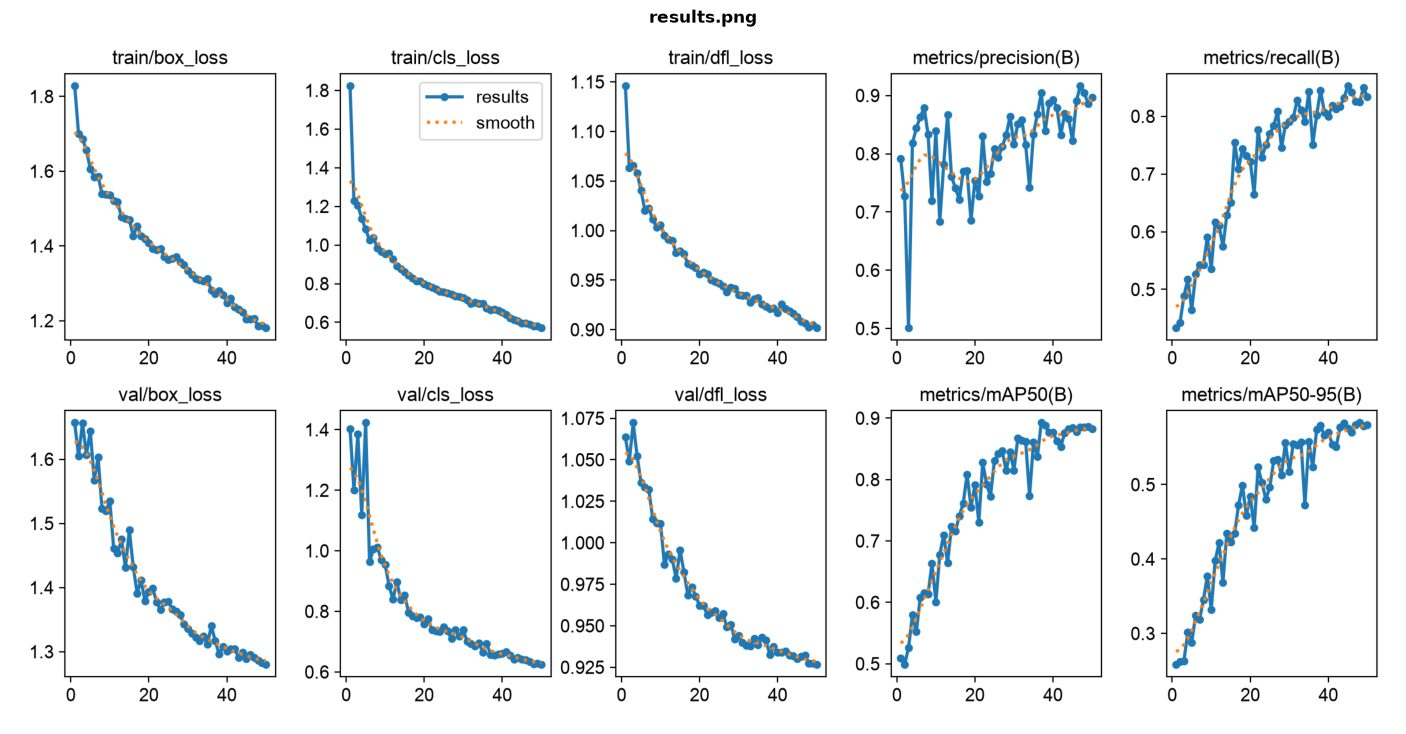

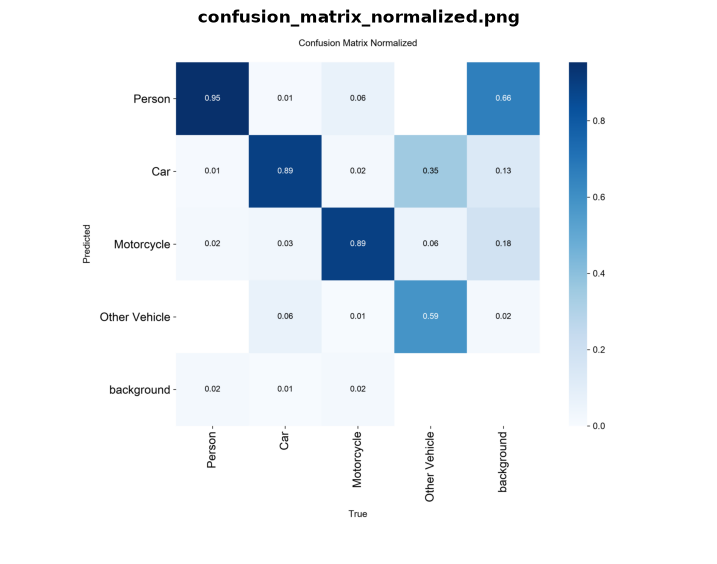

In [8]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Training curves and test-set confusion matrix
TEST_DIR = os.path.join(RUNS_DIR, 'test')
for path, size in [(os.path.join(TRAIN_DIR, 'results.png'), (18, 9)),
                   (os.path.join(TEST_DIR, 'confusion_matrix_normalized.png'), (9, 7))]:
    if os.path.exists(path):
        plt.figure(figsize=size)
        plt.imshow(mpimg.imread(path))
        plt.title(os.path.basename(path), fontweight='bold')
        plt.axis('off')
        plt.show()


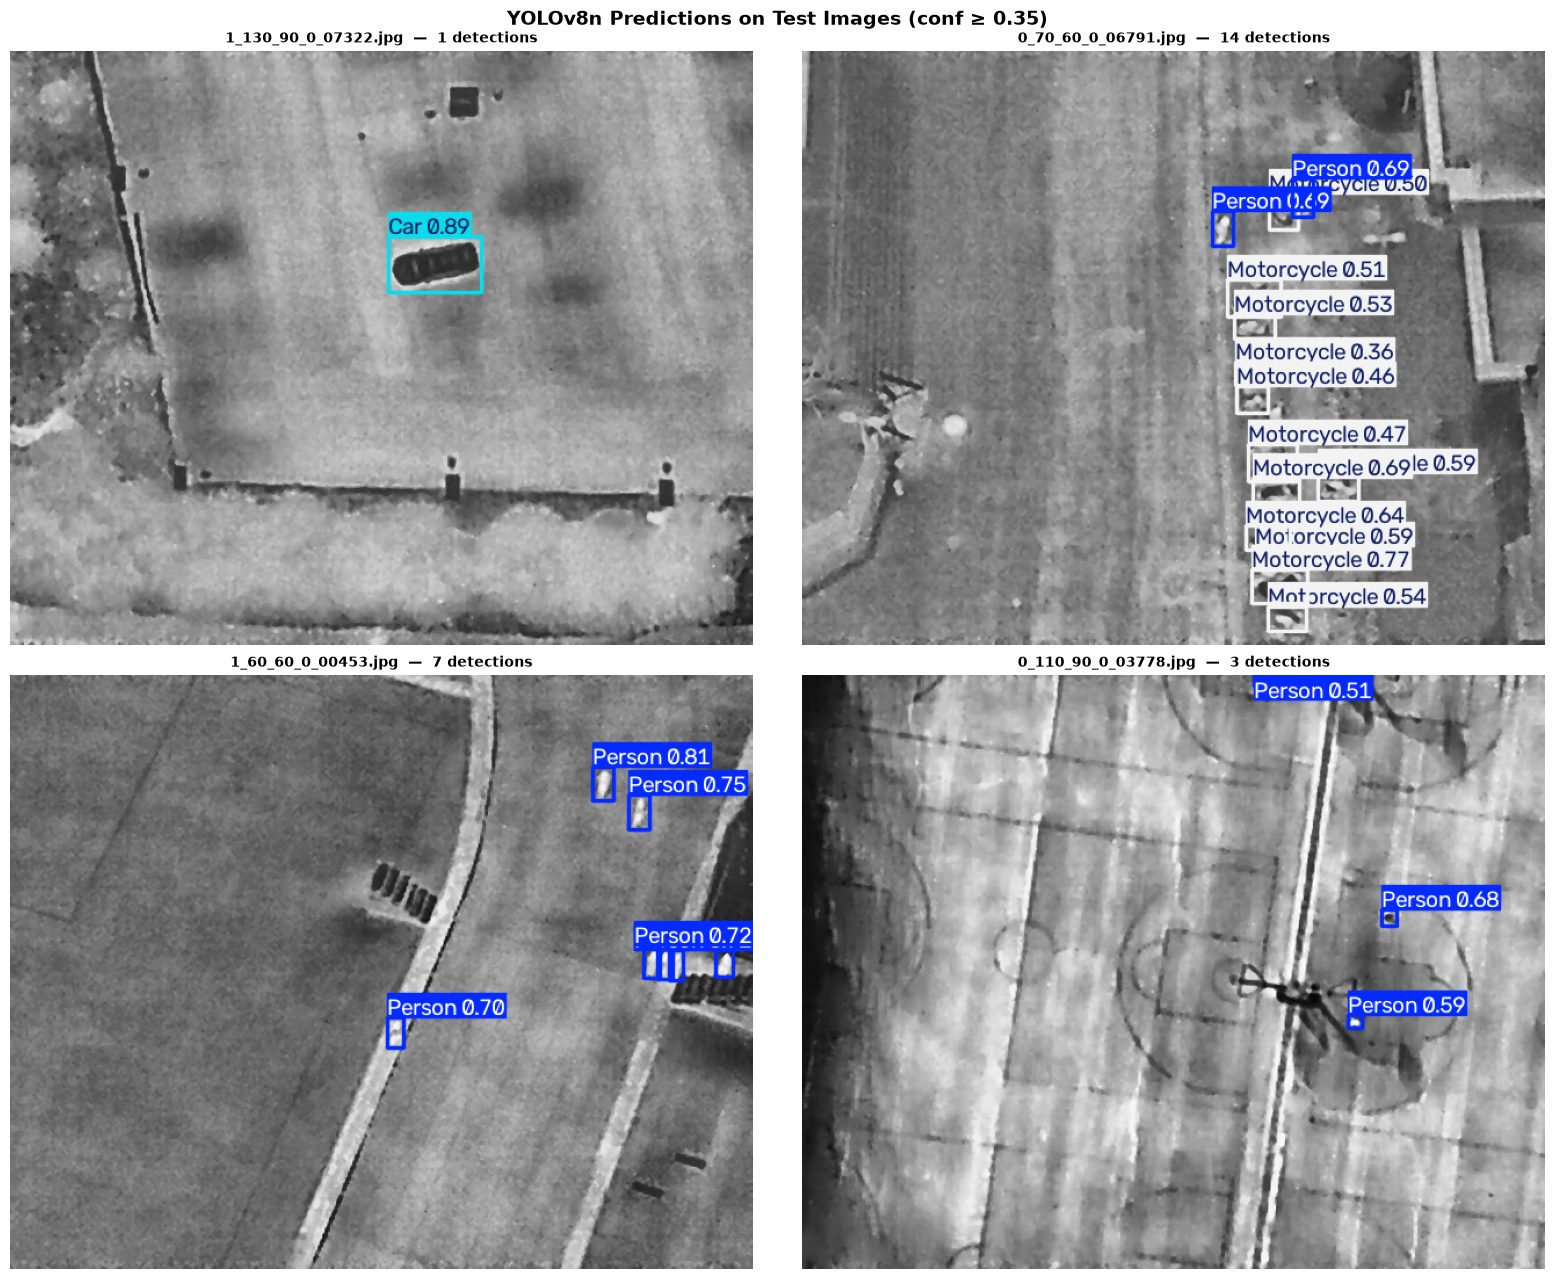

In [9]:
import glob
import random
import cv2

# Qualitative check: predictions on random test images
random.seed(7)
test_imgs = random.sample(sorted(glob.glob(os.path.join(DATA_ROOT, 'hit-uav-processed', 'images', 'test', '*.jpg'))), 4)

fig, axes = plt.subplots(2, 2, figsize=(16, 13))
for ax, img_path in zip(axes.flatten(), test_imgs):
    res = best(img_path, conf=0.35, verbose=False)[0]
    ax.imshow(cv2.cvtColor(res.plot(line_width=2), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{os.path.basename(img_path)}  —  {len(res.boxes)} detections", fontsize=10, fontweight='bold')
    ax.axis('off')
plt.suptitle('YOLOv8n Predictions on Test Images (conf ≥ 0.35)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


### 6.2 Our Model's Results (50 epochs, preprocessed data)

Held-out **test split** (571 images, 4,780 boxes), from the evaluation cell above:

| Class | Precision | Recall | mAP50 | mAP50-95 |
|---|---:|---:|---:|---:|
| **All** | **0.887** | **0.812** | **0.867** | **0.575** |
| Person | 0.906 | 0.862 | 0.921 | 0.487 |
| Car | 0.931 | 0.954 | 0.976 | 0.731 |
| Motorcycle | 0.926 | 0.812 | 0.901 | 0.561 |
| Other Vehicle | 0.784 | 0.618 | 0.670 | 0.520 |

> **Interpretation:**
> - The Car class performs best → large heat signature, distinctive shape
> - Person and Motorcycle are good → medium size, distinct heat
> - Other Vehicle is low → heterogeneous class (trucks, buses, tractors...) with very few training examples

### 6.3 Interpreting the Training Plots

Files generated under `runs/detect/train/`:

| File | Content |
|---|---|
| `results.png` | Loss and metric plots (per epoch) |
| `confusion_matrix.png` | Inter-class confusion matrix |
| `PR_curve.png` | Precision-Recall curve |
| `F1_curve.png` | F1 vs confidence threshold |
| `labels.jpg` | Label distribution (position + size) |
| `weights/best.pt` | Weights at the best validation mAP50 |
| `weights/last.pt` | Last epoch weights |

### 6.4 Contribution of Preprocessing

**Effect of spatial filtering:**
- **Median filter (3×3):** Reduces thermal sensor noise → cleaner object boundaries
- **CLAHE:** Improves local contrast → objects in dark regions become more visible
- **Unsharp Masking:** Sharpens object edges → YOLOv8's convolutional layers extract stronger features

### 6.5 Downloading the Model and Deployment

```python
# In Colab, after training finishes:
from google.colab import files
files.download('/content/runs/detect/train/weights/best.pt')

# Then move it to your local machine (locally it is already at runs/detect/train/weights/best.pt):
# mv ~/Downloads/best.pt backend/models/best.pt
# make dev   ← FastAPI + Next.js interface
```